# BYD no tiene un millón de empleados: compruebo la dimensión real

## Pregunta

Quiero comprobar dos afirmaciones publicadas el 28 de octubre de 2026: que BYD tiene un millón de empleados y que su plantilla supera la suma de Toyota, General Motors, Ford y Tesla.

Este es un **EDA descriptivo**, no una predicción. Trabajo con las plantillas consolidadas más recientes publicadas por cada empresa. Las fechas no coinciden exactamente y Ford y General Motors redondean sus cifras a miles, por lo que trato la suma como aproximada.

## Fuentes

- BYD, informe de sostenibilidad de 2025 y memorias anuales.
- Toyota, formulario 20-F del ejercicio cerrado el 31 de marzo de 2026.
- Ford, informe anual de 2025.
- General Motors, formulario 10-K de 2025.
- Tesla, formulario 10-K de 2025.

Los CSV conservan la URL y el alcance de cada cifra.

In [1]:
# cargo las tablas preparadas a partir de los informes originales
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

base = Path.cwd()
datos = base / "datos"

historica = pd.read_csv(datos / "byd_plantilla_historica.csv")
comparacion = pd.read_csv(datos / "comparacion_plantillas.csv", parse_dates=["fecha"])
composicion = pd.read_csv(datos / "byd_composicion_2025.csv")

display(historica)
display(comparacion[["empresa", "empleados", "fecha", "precision", "alcance"]])
display(composicion)

   anio  ...                               nota
0  2021  ...  Plantilla al cierre del ejercicio
1  2022  ...  Plantilla al cierre del ejercicio
2  2023  ...  Plantilla al cierre del ejercicio
3  2024  ...  Plantilla al cierre del ejercicio
4  2025  ...  Plantilla al cierre del ejercicio

[5 rows x 4 columns]
          empresa  ...                                  alcance
0             BYD  ...                        Grupo consolidado
1          Toyota  ...                        Grupo consolidado
2            Ford  ...                    Empresa y Ford Credit
3  General Motors  ...  Grupo consolidado incluido GM Financial
4           Tesla  ...                        Plantilla mundial

[5 rows x 5 columns]
   dimension                          categoria  empleados  porcentaje
0    funcion                         Produccion     665812       76.56
1    funcion                            Tecnica     127665       14.68
2    funcion                             Ventas      40348        4.64


## 1. Reconstruyo el camino hasta el supuesto millón

No redondeo 968.872 a un millón cuando la noticia habla de la plantilla actual. Esa cifra corresponde al cierre de 2024. Para 2025, el mismo grupo declara 869.622 personas.

In [2]:
# calculo los cambios sin ocultar la caída del último ejercicio
historica["cambio"] = historica["empleados"].diff()
historica["cambio_pct"] = historica["empleados"].pct_change() * 100

inicio = historica.iloc[0]
maximo = historica.loc[historica["empleados"].idxmax()]
actual = historica.iloc[-1]

resumen_historico = {
    "empleados_2021": int(inicio.empleados),
    "maximo_anio": int(maximo.anio),
    "maximo_empleados": int(maximo.empleados),
    "empleados_2025": int(actual.empleados),
    "cambio_2024_2025": int(actual.cambio),
    "cambio_pct_2024_2025": round(float(actual.cambio_pct), 2),
    "crecimiento_pct_2021_2025": round((actual.empleados / inicio.empleados - 1) * 100, 2),
}
resumen_historico

{'empleados_2021': 288186, 'maximo_anio': 2024, 'maximo_empleados': 968872, 'empleados_2025': 869622, 'cambio_2024_2025': -99250, 'cambio_pct_2024_2025': -10.24, 'crecimiento_pct_2021_2025': np.float64(201.76)}


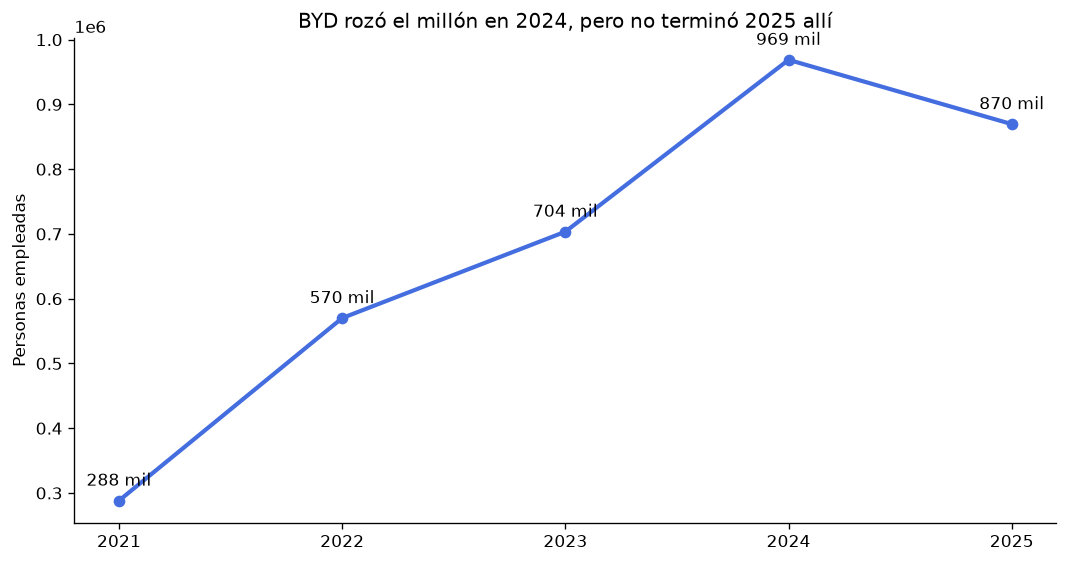

In [3]:
# dibujo toda la serie para que el máximo de 2024 no parezca la cifra vigente
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(historica["anio"], historica["empleados"], color="#446ddf", marker="o", linewidth=2.5)
for _, fila in historica.iterrows():
    ax.annotate(f'{fila.empleados/1000:,.0f} mil'.replace(',', '.'),
                (fila.anio, fila.empleados), xytext=(0, 9), textcoords="offset points", ha="center")
ax.set_title("BYD rozó el millón en 2024, pero no terminó 2025 allí")
ax.set_ylabel("Personas empleadas")
ax.set_xticks(historica["anio"])
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Mi lectura.** Entre 2021 y 2025 la plantilla creció un 201,8%: se triplicó. Sin embargo, el último movimiento fue una reducción de 99.250 personas, un 10,2%. La dimensión sigue siendo extraordinaria, pero «un millón de empleados» convierte el máximo de un año anterior en una cifra actual.

## 2. Pongo a prueba la comparación con cuatro fabricantes

Sumo Toyota, Ford, General Motors y Tesla con sus últimas memorias disponibles a 29 de octubre de 2026. Toyota cierra en marzo; las demás, en diciembre. Ford y General Motors publican cifras aproximadas en miles. Por eso no presento la diferencia como un recuento exacto persona a persona.

In [4]:
# separo byd de las cuatro empresas y calculo una diferencia aproximada
byd = int(comparacion.loc[comparacion["empresa"] == "BYD", "empleados"].iloc[0])
rivales = comparacion.loc[comparacion["empresa"] != "BYD"].copy()
suma_rivales = int(rivales["empleados"].sum())
diferencia = byd - suma_rivales
margen_pct = (byd / suma_rivales - 1) * 100

resumen_comparacion = {
    "byd": byd,
    "suma_toyota_gm_ford_tesla": suma_rivales,
    "diferencia_aproximada": diferencia,
    "margen_pct": round(margen_pct, 2),
}
resumen_comparacion

{'byd': 869622, 'suma_toyota_gm_ford_tesla': 849712, 'diferencia_aproximada': 19910, 'margen_pct': 2.34}


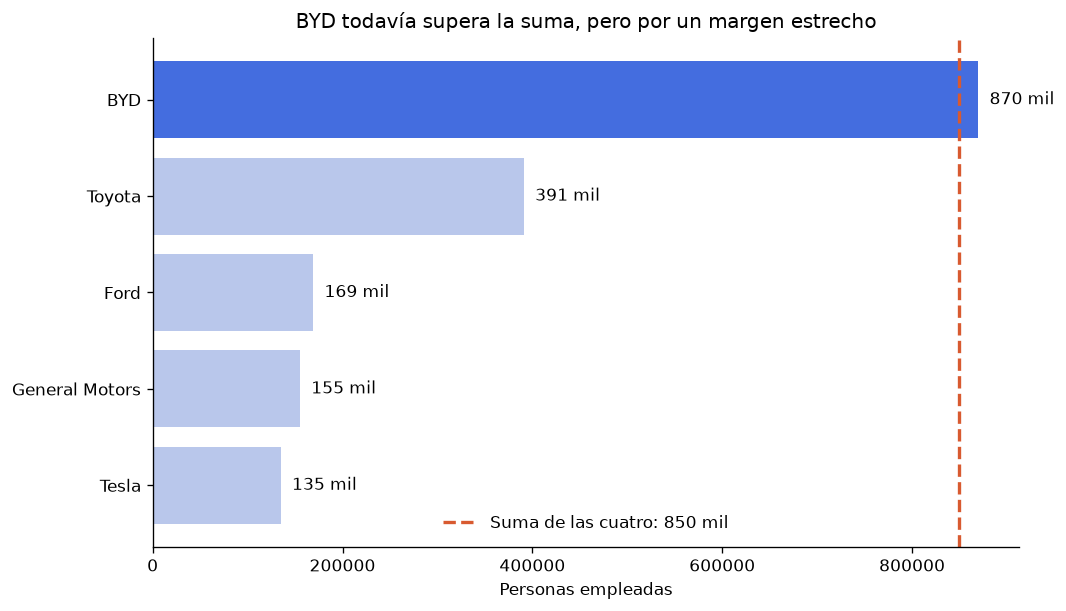

In [5]:
# muestro las cinco empresas y la suma que sostiene el titular
orden = comparacion.sort_values("empleados")
fig, ax = plt.subplots(figsize=(9, 5.2))
colores = ["#446ddf" if empresa == "BYD" else "#b9c7eb" for empresa in orden["empresa"]]
ax.barh(orden["empresa"], orden["empleados"], color=colores)
for i, valor in enumerate(orden["empleados"]):
    ax.text(valor + 12000, i, f'{valor/1000:,.0f} mil'.replace(',', '.'), va="center")
ax.axvline(suma_rivales, color="#d85a30", linestyle="--", linewidth=2,
           label=f'Suma de las cuatro: {suma_rivales/1000:,.0f} mil'.replace(',', '.'))
ax.set_title("BYD todavía supera la suma, pero por un margen estrecho")
ax.set_xlabel("Personas empleadas")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Mi lectura.** Con estas memorias, Toyota, Ford, General Motors y Tesla suman aproximadamente 849.712 personas. BYD las supera en unas 19.910, apenas un 2,3%. La segunda mitad del titular se sostiene con los últimos cierres, pero depende de cifras redondeadas, fechas diferentes y perímetros empresariales que no son idénticos.

## 3. Miro dentro de la plantilla de BYD

La comparación no describe cinco fábricas de coches equivalentes. BYD también fabrica baterías, electrónica, semiconductores y otros componentes. Su integración vertical ayuda a explicar por qué concentra tantas tareas dentro del grupo, aunque las categorías publicadas no permiten asignar cada persona a un producto concreto.

In [6]:
# resumo la composición sin atribuir a cada empleo un producto que el informe no identifica
funciones = composicion.query("dimension == 'funcion'").sort_values("empleados", ascending=False)
ubicacion = composicion.query("dimension == 'ubicacion'")

produccion = int(funciones.loc[funciones["categoria"] == "Produccion", "empleados"].iloc[0])
tecnica = int(funciones.loc[funciones["categoria"] == "Tecnica", "empleados"].iloc[0])
china = int(ubicacion.loc[ubicacion["categoria"] == "China continental", "empleados"].iloc[0])

resumen_composicion = {
    "produccion": produccion,
    "produccion_pct": round(produccion / byd * 100, 2),
    "tecnica": tecnica,
    "tecnica_pct": round(tecnica / byd * 100, 2),
    "china_continental": china,
    "china_continental_pct": round(china / byd * 100, 2),
}
resumen_composicion

{'produccion': 665812, 'produccion_pct': 76.56, 'tecnica': 127665, 'tecnica_pct': 14.68, 'china_continental': 837518, 'china_continental_pct': 96.31}


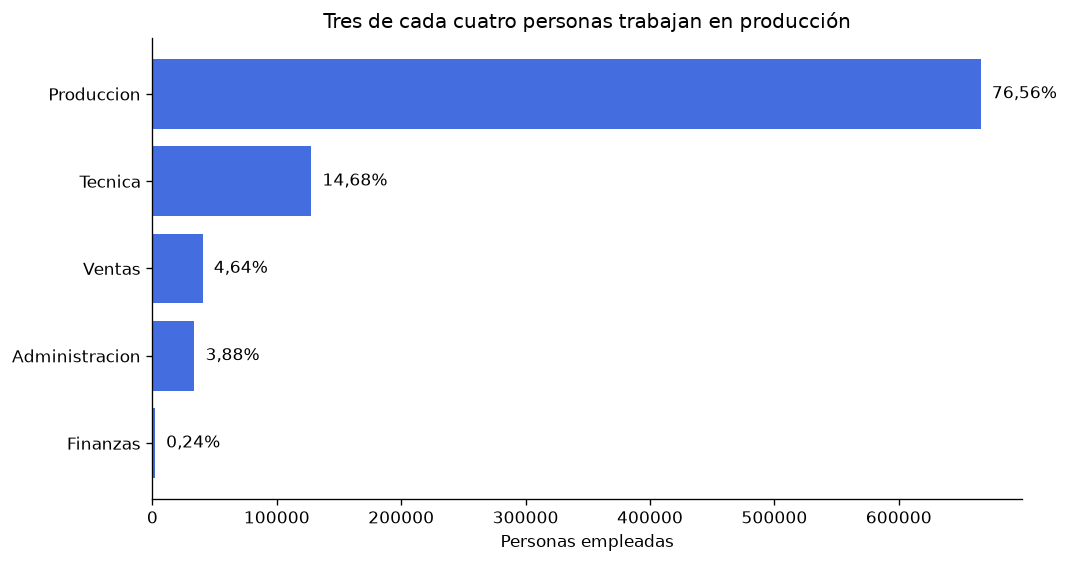

In [7]:
# comparo las funciones declaradas por byd en 2025
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(funciones["categoria"], funciones["empleados"], color="#446ddf")
ax.invert_yaxis()
for i, fila in enumerate(funciones.itertuples()):
    ax.text(fila.empleados + 9000, i, f"{fila.porcentaje:.2f}%".replace('.', ','), va="center")
ax.set_title("Tres de cada cuatro personas trabajan en producción")
ax.set_xlabel("Personas empleadas")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Mi lectura.** BYD clasifica 665.812 personas en producción, el 76,6% de su plantilla, y 127.665 en funciones técnicas. Además, el 96,3% trabaja en China continental. Esto muestra una gran estructura industrial concentrada, pero no demuestra por sí solo que BYD sea menos eficiente: la empresa conserva dentro del grupo actividades que otras compañías pueden comprar a proveedores.

## 4. Conclusión y límites

- **No puedo afirmar que BYD tenga hoy un millón de empleados.** El dato vigente al cierre de 2025 es 869.622.
- **Sí puedo afirmar, con cautela, que su última plantilla publicada supera la suma de Toyota, Ford, General Motors y Tesla.** La ventaja calculada es de unas 19.910 personas, un 2,3%.
- La comparación es aproximada: Toyota cierra tres meses después y Ford y General Motors redondean a miles.
- Las plantillas son consolidadas, pero los grupos no hacen exactamente lo mismo ni externalizan las mismas actividades.
- No uso la plantilla como medida aislada de productividad y no genero ninguna predicción.

In [8]:
# exporto los resultados comprobados para reutilizarlos sin transcribir cifras
resultados = {
    **resumen_historico,
    **resumen_comparacion,
    **resumen_composicion,
    "fecha_corte": "2026-10-29",
}

(base / "resultados.json").write_text(
    json.dumps(resultados, ensure_ascii=False, indent=2), encoding="utf-8"
)

assert resultados["empleados_2025"] == 869622
assert resultados["suma_toyota_gm_ford_tesla"] == 849712
assert resultados["diferencia_aproximada"] == 19910
resultados

{'empleados_2021': 288186, 'maximo_anio': 2024, 'maximo_empleados': 968872, 'empleados_2025': 869622, 'cambio_2024_2025': -99250, 'cambio_pct_2024_2025': -10.24, 'crecimiento_pct_2021_2025': np.float64(201.76), 'byd': 869622, 'suma_toyota_gm_ford_tesla': 849712, 'diferencia_aproximada': 19910, 'margen_pct': 2.34, 'produccion': 665812, 'produccion_pct': 76.56, 'tecnica': 127665, 'tecnica_pct': 14.68, 'china_continental': 837518, 'china_continental_pct': 96.31, 'fecha_corte': '2026-10-29'}
